# CALOR Y MAYORES EN MADRID

## Ingeniería de variables: malla de hexágonos H3 y variables por hexágono

Cada hexágono H3 de resolución 9 (unos 0,1 km²) será una fila del modelo: su temperatura de superficie (variable objetivo) y sus variables de forma urbana (predictoras).

## 1. Malla de hexágonos

In [1]:
import sys
import pandas as pd
import geopandas as gpd
import h3
import numpy as np
from shapely.geometry import Polygon
from rasterstats import zonal_stats
import glob
import rasterio
from rasterio.merge import merge

In [2]:
sys.path.append("../scrips")
from config import RUTA_RAW, RUTA_CLEAN, CRS_PROYECTO

- calculamos los hexágonos que cubren el término municipal

In [3]:
termino = gpd.read_file(RUTA_RAW + "limites/Termino_municipal/TERMINO_MUNICIPAL.shp")
termino_wgs84 = termino.to_crs(epsg=4326)
celdas = h3.geo_to_cells(termino_wgs84.geometry.iloc[0], res=9)
print("Hexágonos en el término:", len(celdas))

Hexágonos en el término: 5567


In [4]:
poligonos = []
for celda in celdas:
    contorno = h3.cell_to_boundary(celda)
    vertices = [(lng, lat) for lat, lng in contorno]
    poligonos.append(Polygon(vertices))

hexagonos = gpd.GeoDataFrame({"h3": list(celdas)}, geometry=poligonos, crs="EPSG:4326")
hexagonos = hexagonos.to_crs(CRS_PROYECTO)
print(hexagonos.shape)
print("Área media (m²):", round(hexagonos.area.mean()))

(5567, 2)
Área media (m²): 108383


- mapa de comprobación con los centros

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

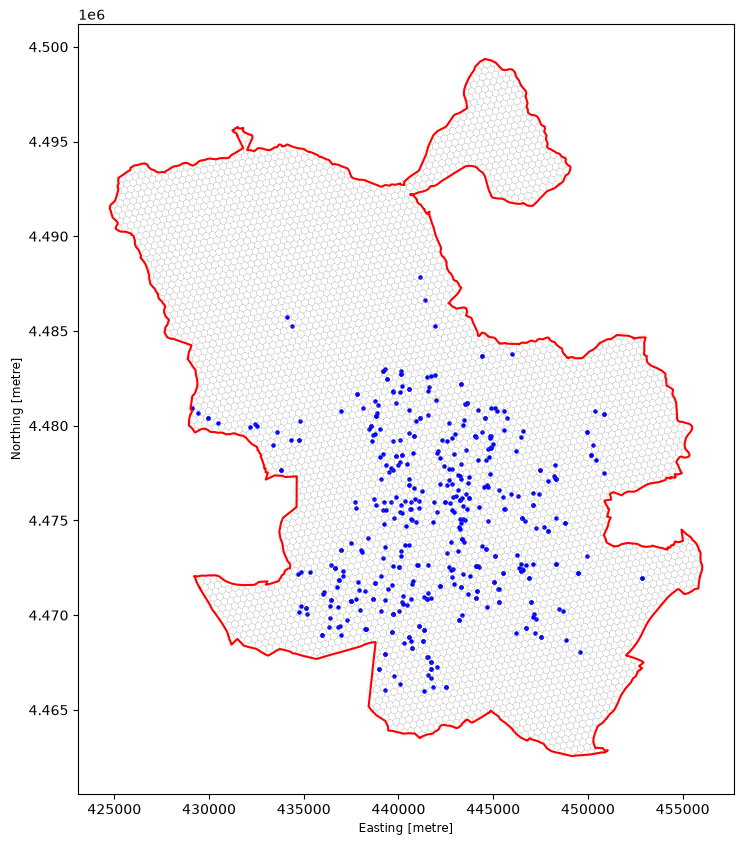

In [5]:
centros = gpd.read_file(RUTA_CLEAN + "centros_mayores.gpkg")
ax = hexagonos.boundary.plot(linewidth=0.1, color="grey", figsize=(10, 10))
termino.boundary.plot(ax=ax, color="red")
centros.plot(ax=ax, color="blue", markersize=5)

**Observación:** 5.567 hexágonos H3 de resolución 9 cubren el término municipal, con un área media de 0,11 km².

## 2. Máscara urbana

- cargamos la máscara urbana del Urban Atlas 2021 (zona urbana oficial de la FUA de Madrid)

In [6]:
ruta_mascara = RUTA_RAW + "dato7/7253/Results/CLMS_UA_STL_S2021_V005ha_ES001L3_MADRID_03035_V01_R02_20251121/CLMS_UA_UM_S2021_V005ha_ES001L3_MADRID_03035_V01_R02_20251121.fgb"
mascara = gpd.read_file(ruta_mascara).to_crs(CRS_PROYECTO)
mascara_union = mascara.union_all()
print(mascara.shape)

(10598, 2)


- marcamos como urbanos los hexágonos cuyo centro cae dentro de la máscara

In [7]:
hexagonos["urbano"] = hexagonos.centroid.within(mascara_union)
hexagonos["urbano"].value_counts()

urbano
True     2921
False    2646
Name: count, dtype: int64

- comprobamos en qué hexágonos caen los centros de mayores

In [8]:
centros_hex = gpd.sjoin(centros, hexagonos, how="left", predicate="within")
centros_hex["urbano"].value_counts(dropna=False)

urbano
True     427
False     12
Name: count, dtype: int64

- mapa de la máscara

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

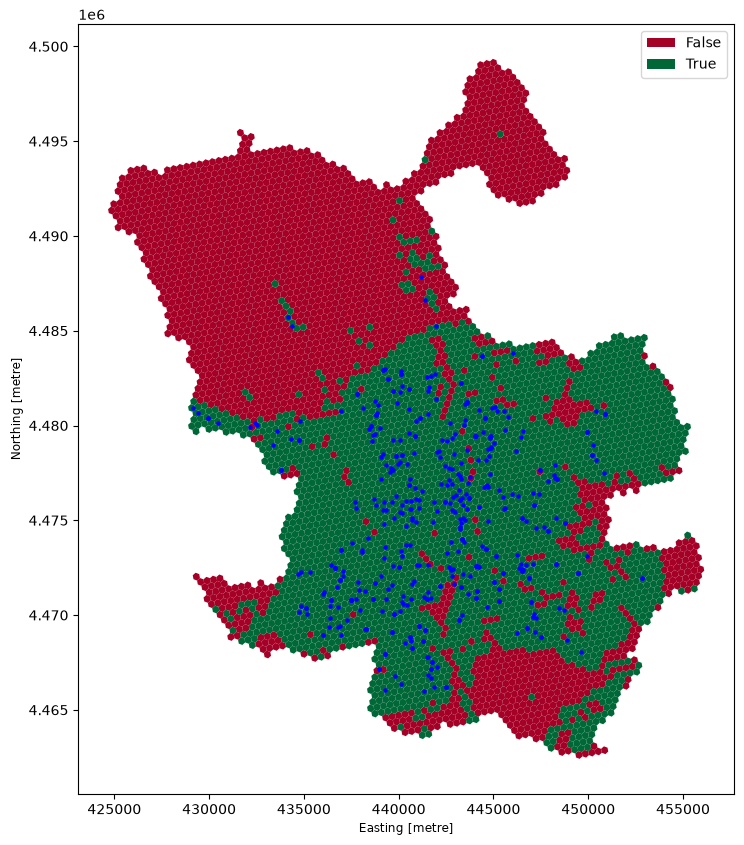

In [9]:
ax = hexagonos.plot(column="urbano", cmap="RdYlGn", figsize=(10, 10), legend=True)
centros.plot(ax=ax, color="blue", markersize=5)

**Observaciones:**
- Máscara: 2.921 hexágonos urbanos (52 %) y 2.646 no urbanos (Monte de El Pardo, descampados del sureste y corredores ferroviarios).
- Centros: 427 de 439 centros caen en hexágonos urbanos; 12 caen en hexágonos no urbanos.

**Decisión:** se marcan como urbanos los hexágonos que contienen algún centro de mayores, aunque la máscara urbana los excluya, para que todos los centros tengan su hexágono en el modelo.

In [10]:
hexagonos_con_centro = centros_hex["h3"].unique()
hexagonos.loc[hexagonos["h3"].isin(hexagonos_con_centro), "urbano"] = True
hexagonos["urbano"].value_counts()

urbano
True     2931
False    2636
Name: count, dtype: int64

- guardamos la malla con la marca de zona urbana

In [11]:
hexagonos.to_file(RUTA_CLEAN + "hexagonos_h3.gpkg", driver="GPKG")

## 3. Variables desde los ráster: temperatura, NDVI y albedo

- calculamos la media de cada ráster dentro de cada hexágono (estadísticas zonales)

In [12]:
estadisticas_lst = zonal_stats(hexagonos, RUTA_RAW + "dato4y5/lst_summer_madrid_2023_2026.tif", stats=["mean", "count"])
hexagonos["lst"] = [e["mean"] for e in estadisticas_lst]
hexagonos["lst_pixeles"] = [e["count"] for e in estadisticas_lst]
hexagonos[["lst", "lst_pixeles"]].describe()

c:\Users\Usuario\anaconda3\Lib\site-packages\rasterstats\io.py:437: NodataWarning: Setting nodata to -999; specify nodata explicitly
  warnings.warn(


,lst,lst_pixeles
count,5567.000000,5567.000000
mean,46.396717,120.410095
std,3.085642,1.432689
min,29.757862,58.000000
25%,44.283881,120.000000
50%,46.443321,121.000000
75%,48.537654,121.000000
max,55.738333,123.000000


**Observación:** todos los hexágonos tienen temperatura (unos 120 píxeles cada uno); la media es de 46,4 °C y el rango va de 29,8 a 55,7 °C.

- repetimos con el NDVI y el albedo (Sentinel-2, 10 m)

In [13]:
estadisticas_ndvi = zonal_stats(hexagonos, RUTA_RAW + "dato4y5/ndvi_summer_madrid_2023_2026.tif", stats=["mean"])
hexagonos["ndvi"] = [e["mean"] for e in estadisticas_ndvi]

estadisticas_albedo = zonal_stats(hexagonos, RUTA_RAW + "dato4y5/albedo_summer_madrid_2023_2026.tif", stats=["mean"])
hexagonos["albedo"] = [e["mean"] for e in estadisticas_albedo]

hexagonos[["ndvi", "albedo"]].describe()

,ndvi,albedo
count,5567.000000,5567.000000
mean,0.256394,0.198636
std,0.104838,0.033069
min,-0.265963,0.027061
25%,0.178343,0.177711
50%,0.260256,0.192174
75%,0.331133,0.212670
max,0.720527,0.402915


**Observación:** NDVI medio de 0,26 (de −0,27 a 0,72) y albedo medio de 0,20 (de 0,03 a 0,40); al promediar por hexágono desaparecen los píxeles extremos que vimos en el ráster.

- mapa de la temperatura por hexágono

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

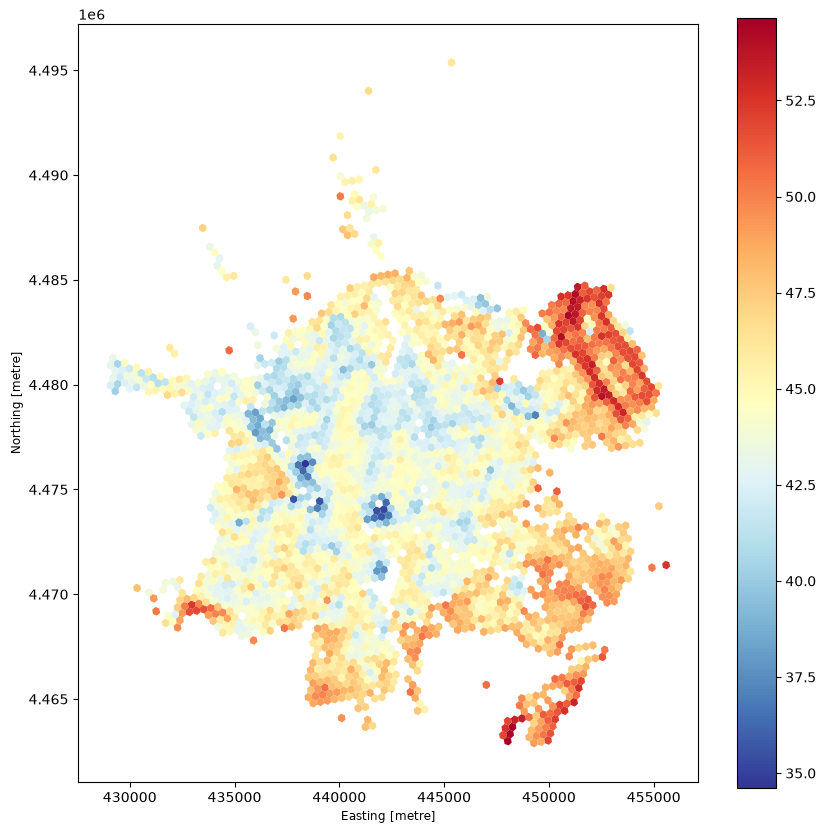

In [14]:
hexagonos[hexagonos["urbano"]].plot(column="lst", cmap="RdYlBu_r", legend=True, figsize=(10, 10))

**Observación:** las zonas más calientes son el aeropuerto de Barajas, los polígonos industriales del este y del sur y Valdemingómez; las más frescas, la Casa de Campo, El Retiro y el corredor del Manzanares. El centro histórico no es lo más caliente.

## 4. Variables del Catastro

- cargamos los edificios y las partes de edificio, solo con las columnas necesarias

In [15]:
edificios = gpd.read_file(RUTA_RAW + "dato6/catastro_edificios.gpkg", columns=["localId", "currentUse", "beginning"])
partes = gpd.read_file(RUTA_RAW + "dato6/catastro_partes.gpkg", columns=["localId", "numberOfFloorsAboveGround"])
print(edificios.shape, partes.shape)

(124396, 4) (811691, 3)


**Observación:** se cargan los 124.396 edificios y las 811.691 partes, solo con las columnas necesarias.

- preparamos el año de construcción, las áreas y la superficie construida

In [16]:
edificios["anio"] = pd.to_numeric(edificios["beginning"].astype(str).str[:4], errors="coerce")
partes["plantas"] = partes["numberOfFloorsAboveGround"]

print("Edificios sin año:", edificios["anio"].isnull().sum())
edificios["anio"].describe()

Edificios sin año: 241


count    124155.000000
mean       1968.252306
std          28.681018
min        1114.000000
25%        1956.000000
50%        1968.000000
75%        1988.000000
max        2026.000000
Name: anio, dtype: float64

**Observación:** 241 edificios sin año (0,2 %); la mediana es 1968 y el máximo 2026. El mínimo, 1114, es probablemente un error de registro y se revisará en el análisis exploratorio.

- recortamos cada edificio y cada parte por los bordes de los hexágonos, para repartir su superficie entre los hexágonos que ocupa

In [17]:
hexagonos_base = hexagonos[["h3", "geometry"]]

edificios_trozos = gpd.overlay(edificios[["currentUse", "anio", "geometry"]], hexagonos_base, how="intersection")
edificios_trozos["area"] = edificios_trozos.area
edificios_trozos["area_industrial"] = edificios_trozos["area"].where(edificios_trozos["currentUse"] == "3_industrial", 0)
edificios_trozos["anio_x_area"] = edificios_trozos["anio"] * edificios_trozos["area"]
edificios_trozos["area_con_anio"] = edificios_trozos["area"].where(edificios_trozos["anio"].notnull(), 0)

partes_trozos = gpd.overlay(partes[["plantas", "geometry"]], hexagonos_base, how="intersection")
partes_trozos["area"] = partes_trozos.area
partes_trozos["superficie_construida"] = partes_trozos["area"] * partes_trozos["plantas"]
partes_trozos["plantas_x_area"] = partes_trozos["plantas"] * partes_trozos["area"]
partes_trozos["area_con_plantas"] = partes_trozos["area"].where(partes_trozos["plantas"] > 0, 0)

print(edificios_trozos.shape, partes_trozos.shape)

(142248, 8) (850301, 7)


**Observación:** el recorte genera 142.248 trozos de edificio y 850.301 de partes: los edificios que ocupan varios hexágonos se reparten ahora entre ellos.

- sumamos por hexágono

In [18]:
resumen_edificios = edificios_trozos.groupby("h3")[["area", "area_industrial", "anio_x_area", "area_con_anio"]].sum()
resumen_partes = partes_trozos.groupby("h3")[["superficie_construida", "plantas_x_area", "area_con_plantas"]].sum()

- calculamos las variables finales y las unimos a la malla

In [19]:
hexagonos = hexagonos.merge(resumen_edificios, on="h3", how="left")
hexagonos = hexagonos.merge(resumen_partes, on="h3", how="left")

area_hexagono = hexagonos.area
hexagonos["pct_edificado"] = (hexagonos["area"].fillna(0) / area_hexagono * 100).round(2)
hexagonos["pct_industrial"] = (hexagonos["area_industrial"].fillna(0) / area_hexagono * 100).round(2)
hexagonos["edificabilidad"] = (hexagonos["superficie_construida"].fillna(0) / area_hexagono).round(3)
hexagonos["plantas_media"] = (hexagonos["plantas_x_area"] / hexagonos["area_con_plantas"]).round(2)
hexagonos["anio_medio"] = (hexagonos["anio_x_area"] / hexagonos["area_con_anio"]).round(0)

hexagonos = hexagonos.drop(columns=["area", "area_industrial", "anio_x_area", "area_con_anio",
                                    "superficie_construida", "plantas_x_area", "area_con_plantas"])
hexagonos[["pct_edificado", "pct_industrial", "edificabilidad", "plantas_media", "anio_medio"]].describe()

,pct_edificado,pct_industrial,edificabilidad,plantas_media,anio_medio
count,5567.000000,5567.000000,5567.000000,2867.000000,2866.000000
mean,9.146619,0.933700,0.360391,3.354991,1979.795185
std,14.434135,4.175583,0.654986,2.158928,24.002434
min,0.000000,0.000000,0.000000,1.000000,1710.000000
25%,0.000000,0.000000,0.000000,1.340000,1967.000000
50%,0.070000,0.000000,0.001000,3.030000,1980.000000
75%,15.470000,0.010000,0.480000,4.820000,1997.000000
max,99.520000,69.080000,4.061000,16.880000,2026.000000


**Observación:** el % edificado llega como máximo al 99,5 % y el industrial al 69 %, valores ya posibles; la mitad de los hexágonos apenas tiene edificios porque la malla incluye las zonas no urbanas. Altura media de 3,4 plantas y año medio de 1980.

**Decisión:** los edificios y las partes se recortan por los bordes de los hexágonos en lugar de asignarlos por su centro, porque los edificios muy grandes (terminales del aeropuerto, naves, hospitales) ocupan varios hexágonos y con el centro se superaba el 100 % de suelo edificado.

In [20]:
hexagonos.to_file(RUTA_CLEAN + "hexagonos_h3.gpkg", driver="GPKG")

## 5. Vegetación: copa de árboles y arbolado municipal

- cargamos la copa de árboles del Urban Atlas 2021 y la pasamos al sistema del proyecto

In [21]:
ruta_copa = RUTA_RAW + "dato7/7253/Results/CLMS_UA_STL_S2021_V005ha_ES001L3_MADRID_03035_V01_R02_20251121/CLMS_UA_STL_S2021_V005ha_ES001L3_MADRID_03035_V01_R02_20251121.fgb"
copa = gpd.read_file(ruta_copa).to_crs(CRS_PROYECTO)
print(copa.shape)

(41210, 7)


- recortamos la copa por los hexágonos y calculamos su porcentaje

In [22]:
copa_trozos = gpd.overlay(copa[["geometry"]], hexagonos_base, how="intersection")
copa_trozos["area_copa"] = copa_trozos.area
resumen_copa = copa_trozos.groupby("h3")[["area_copa"]].sum()

hexagonos = hexagonos.merge(resumen_copa, on="h3", how="left")
hexagonos["pct_copa"] = (hexagonos["area_copa"].fillna(0) / hexagonos.area * 100).round(2)
hexagonos = hexagonos.drop(columns=["area_copa"])
hexagonos["pct_copa"].describe()

count    5567.000000
mean        7.183106
std        16.192464
min         0.000000
25%         0.000000
50%         0.000000
75%         7.060000
max       100.000000
Name: pct_copa, dtype: float64

**Observación:** de media un 7 % del hexágono es copa de árboles, pero más de la mitad de los hexágonos no tiene ninguna; algunos llegan al 100 % (zonas boscosas como la Casa de Campo).

- cargamos el arbolado municipal (un punto por árbol)

In [23]:
arboles = gpd.read_file(RUTA_RAW + "arbolado/300761-1-arbolado-especies-zip/ARBOLADO_MADRID.shp", columns=["ALTURA_TOT"])
print(arboles.shape)
arboles["ALTURA_TOT"].describe()

(793047, 2)


count    793047.000000
mean          7.221143
std           4.152643
min           0.000000
25%           4.000000
50%           6.000000
75%           9.000000
max         600.000000
Name: ALTURA_TOT, dtype: float64

**Observacion:** la altura máxima es de 600 m, y ningún árbol mide eso (los más altos de Madrid rondan los 30-40 m). Probablemente es un error de tecleo (6,00 escrito como 600) y puede haber más. También hay alturas de 0, que no tienen sentido para un árbol existente. Si no lo corregimos, esos valores falsean la altura media de su hexágono.

In [24]:
for limite in [30, 40, 50, 100]:
    print(f"Árboles de más de {limite} m:", (arboles["ALTURA_TOT"] > limite).sum())
print("Árboles con altura 0:", (arboles["ALTURA_TOT"] == 0).sum())

Árboles de más de 30 m: 175
Árboles de más de 40 m: 7
Árboles de más de 50 m: 6
Árboles de más de 100 m: 3
Árboles con altura 0: 931


**Decisión:** las alturas de más de 40 m (7 árboles) y las de 0 m (931) se dejan vacías; esos árboles cuentan para el número de árboles, pero no para la altura media.

In [25]:
arboles.loc[(arboles["ALTURA_TOT"] > 40) | (arboles["ALTURA_TOT"] == 0), "ALTURA_TOT"] = np.nan
arboles["ALTURA_TOT"].describe()

count    792109.000000
mean          7.228366
std           4.088954
min           0.010000
25%           4.000000
50%           6.000000
75%           9.000000
max          40.000000
Name: ALTURA_TOT, dtype: float64

- contamos los árboles y su altura media en cada hexágono

In [26]:
arboles_hex = gpd.sjoin(arboles, hexagonos_base, how="inner", predicate="within")
resumen_arboles = arboles_hex.groupby("h3").agg(
    n_arboles=("ALTURA_TOT", "size"),
    altura_arboles=("ALTURA_TOT", "mean")
)

hexagonos = hexagonos.merge(resumen_arboles, on="h3", how="left")
hexagonos["arboles_ha"] = (hexagonos["n_arboles"].fillna(0) / (hexagonos.area / 10000)).round(1)
hexagonos["altura_arboles"] = hexagonos["altura_arboles"].round(2)
hexagonos = hexagonos.drop(columns=["n_arboles"])
hexagonos[["arboles_ha", "altura_arboles"]].describe()

,arboles_ha,altura_arboles
count,5567.000000,2276.000000
mean,13.121071,7.103163
std,23.515702,2.074807
min,0.000000,1.670000
25%,0.000000,5.490000
50%,0.000000,7.040000
75%,20.100000,8.472500
max,316.400000,19.250000


**Observación:** la mitad de los hexágonos no tiene arbolado municipal (zonas no urbanas y parques forestales no inventariados); el 25 % con más árboles supera los 20 árboles por hectárea. Altura media de 7,1 m, entre 1,7 y 19,3 m.

In [27]:
hexagonos.to_file(RUTA_CLEAN + "hexagonos_h3.gpkg", driver="GPKG")

## 6. Elevación

**Decisión:** las 9 hojas del MDT05 se unen en un mosaico de 25 m de resolución (en lugar de 5 m), suficiente para la altitud media de cada hexágono y mucho más ligero.

- unimos las 9 hojas en un solo ráster recortado al área de los hexágonos

In [28]:
hojas_mdt = glob.glob(RUTA_RAW + "dato8/PNOA_MDT05_*.tif")
print("Hojas encontradas:", len(hojas_mdt))

fuentes = [rasterio.open(hoja) for hoja in hojas_mdt]
mosaico, transformacion = merge(fuentes, bounds=tuple(hexagonos.total_bounds), res=25)

perfil = fuentes[0].profile
perfil.update(height=mosaico.shape[1], width=mosaico.shape[2], transform=transformacion)

with rasterio.open(RUTA_RAW + "dato8/mdt_madrid_25m.tif", "w", **perfil) as destino:
    destino.write(mosaico)

for fuente in fuentes:
    fuente.close()
print("Tamaño del mosaico:", mosaico.shape)

Hojas encontradas: 9
Tamaño del mosaico: (1, 1477, 1258)


**Observación:** las 9 hojas se unen en un solo ráster de 1.477 × 1.258 píxeles de 25 m, que cubre todo el área de los hexágonos.

- calculamos la altitud media de cada hexágono

In [29]:
estadisticas_elevacion = zonal_stats(hexagonos, RUTA_RAW + "dato8/mdt_madrid_25m.tif", stats=["mean"])
hexagonos["elevacion"] = [e["mean"] for e in estadisticas_elevacion]
hexagonos["elevacion"] = hexagonos["elevacion"].round(1)
hexagonos["elevacion"].describe()

count    5567.000000
mean      655.463014
std        43.663822
min       554.000000
25%       623.150000
50%       656.800000
75%       688.100000
max       821.100000
Name: elevacion, dtype: float64

**Observación:** todos los hexágonos tienen altitud, entre 554 y 821 m (media de 655 m), coherente con el relieve de Madrid: más bajo en el valle del Manzanares y más alto en el norte.

In [30]:
hexagonos.to_file(RUTA_CLEAN + "hexagonos_h3.gpkg", driver="GPKG")

## 7. Parques y agua

- cargamos los parques de OpenStreetMap y calculamos su superficie en hectáreas

In [31]:
parques = gpd.read_file(RUTA_RAW + "osm/parks_madrid.gpkg").to_crs(CRS_PROYECTO)
parques["area_ha"] = parques.area / 10000
print(parques.shape)
parques["area_ha"].describe()

(2991, 4)


count    2991.000000
mean        1.955879
std         8.616156
min         0.000257
25%         0.117464
50%         0.312140
75%         0.963550
max       182.591171
Name: area_ha, dtype: float64

- contamos cuántos parques superan distintos tamaños para elegir el umbral de "parque grande"

In [32]:
for limite in [0.5, 1, 2, 5, 10]:
    print(f"Parques de al menos {limite} ha:", (parques["area_ha"] >= limite).sum())

Parques de al menos 0.5 ha: 1154
Parques de al menos 1 ha: 730
Parques de al menos 2 ha: 431
Parques de al menos 5 ha: 194
Parques de al menos 10 ha: 101


**Decisión:** se consideran parques grandes los de al menos 1 ha (730 parques), siguiendo la referencia de la Organización Mundial de la Salud de acceso a zonas verdes de al menos 0,5-1 ha.

In [33]:
parques[parques["name"].str.contains("Casa de Campo", na=False)]

,id,name,geometry,area_ha


**Decisión:** la Casa de Campo no aparece en la capa de parques de OpenStreetMap (está etiquetada como espacio natural). Se añade a los parques grandes con el polígono del barrio administrativo "Casa de Campo", cuyo límite coincide prácticamente con el parque.

In [34]:
barrios = gpd.read_file(RUTA_RAW + "limites/Barrios/BARRIOS.shp")
casa_de_campo = barrios[barrios["NOMBRE"] == "Casa de Campo"][["geometry"]]
print("Barrios encontrados:", len(casa_de_campo))

Barrios encontrados: 1


**Observación:** se encuentra el barrio “Casa de Campo” y se añade a los parques grandes; quedan 731 parques de al menos 1 ha.

- calculamos la distancia del centro de cada hexágono al parque grande más cercano

In [35]:
parques_grandes = parques[parques["area_ha"] >= 1][["geometry"]]
parques_grandes = pd.concat([parques_grandes, casa_de_campo], ignore_index=True)
centroides = gpd.GeoDataFrame(hexagonos[["h3"]], geometry=hexagonos.centroid, crs=CRS_PROYECTO)

distancias = gpd.sjoin_nearest(centroides, parques_grandes[["geometry"]], distance_col="dist_parque_grande")
distancias = distancias.drop_duplicates(subset="h3")

hexagonos = hexagonos.merge(distancias[["h3", "dist_parque_grande"]], on="h3", how="left")
hexagonos["dist_parque_grande"] = hexagonos["dist_parque_grande"].round(1)
hexagonos["dist_parque_grande"].describe()

count    5567.000000
mean     1310.478049
std      1573.043078
min         0.000000
25%       151.850000
50%       607.000000
75%      2005.050000
max      7486.800000
Name: dist_parque_grande, dtype: float64

**Observación:** todos los hexágonos tienen distancia; la mediana es de 607 m y una cuarta parte está a menos de 150 m de un parque grande. Los valores más altos (hasta 7,5 km) son hexágonos no urbanos del norte, lejos de cualquier parque.

In [36]:
hexagonos.to_file(RUTA_CLEAN + "hexagonos_h3.gpkg", driver="GPKG")

- cargamos los usos del suelo del Urban Atlas 2021, solo en el área de los hexágonos

In [37]:
ruta_usos = RUTA_RAW + "dato7/9083/Results/CLMS_UA_LCU_S2021_V025ha_ES001L3_MADRID_03035_V01_R00_20241115/CLMS_UA_LCU_S2021_V025ha_ES001L3_MADRID_03035_V01_R00_20241115.fgb"
usos = gpd.read_file(ruta_usos, bbox=hexagonos)
usos = usos.to_crs(CRS_PROYECTO)
print(usos.shape)
usos.columns

(28273, 11)


Index(['country', 'fua_name', 'fua_code', 'code_2021', 'class_2021',
       'prod_date', 'identifier', 'perimeter', 'area', 'comment', 'geometry'],
      dtype='str')

- revisamos las clases de uso del suelo

In [38]:
usos.head()

,country,fua_name,fua_code,code_2021,class_2021,prod_date,identifier,perimeter,area,comment,geometry
0,ES,Madrid,ES001L3,12100,"Industrial, commercial, public, military and p...",2025-08,57844-ES001L3,4157.666724,249293.291903,None,"MULTIPOLYGON (((440964.762 4461654.643, 440972..."
1,ES,Madrid,ES001L3,12100,"Industrial, commercial, public, military and p...",2025-08,57771-ES001L3,1721.863380,132039.050017,None,"MULTIPOLYGON (((440779.413 4461331.617, 440778..."
2,ES,Madrid,ES001L3,12100,"Industrial, commercial, public, military and p...",2025-08,57641-ES001L3,716.617894,31153.572047,None,"MULTIPOLYGON (((440493.336 4461096.525, 440600..."
3,ES,Madrid,ES001L3,12100,"Industrial, commercial, public, military and p...",2025-08,57543-ES001L3,844.296961,44858.927424,None,"MULTIPOLYGON (((440298.216 4460940.764, 440501..."
4,ES,Madrid,ES001L3,12100,"Industrial, commercial, public, military and p...",2025-08,57513-ES001L3,760.228056,22303.534025,None,"MULTIPOLYGON (((440222.507 4460859.181, 440222..."


- contamos los polígonos de cada clase

In [39]:
usos["code_2021"] = usos["code_2021"].astype(str)
usos.groupby(["code_2021", "class_2021"]).size()

code_2021  class_2021                                                                     
11100      Continuous urban fabric (S.L. : > 80%)                                             7612
11210      Discontinuous dense urban fabric (S.L. : 50% -  80%)                               5193
11220      Discontinuous medium density urban fabric (S.L. : 30% - 50%)                       1968
11230      Discontinuous low density urban fabric (S.L. : 10% - 30%)                          1171
11240      Discontinuous very low density urban fabric (S.L. : < 10%)                          359
11300      Isolated structures                                                                 246
12100      Industrial, commercial, public, military and private units                         4379
12210      Fast transit roads and associated land                                               46
12220      Other roads and associated land                                                      55
12230      Railway

**Observación:** 26 clases; las que usamos son las vías rápidas (46 polígonos), el resto de calles y carreteras (55), el ferrocarril (108) y el agua (61). Hay pocos polígonos de vías porque el Urban Atlas dibuja la red como grandes polígonos continuos.

- porcentaje del hexágono ocupado por calles y carreteras (12210 y 12220) y por ferrocarril (12230)

In [40]:
viario = usos[usos["code_2021"].isin(["12210", "12220"])][["geometry"]]
ferrocarril = usos[usos["code_2021"] == "12230"][["geometry"]]

viario_trozos = gpd.overlay(viario, hexagonos_base, how="intersection")
viario_trozos["area_viario"] = viario_trozos.area
ferrocarril_trozos = gpd.overlay(ferrocarril, hexagonos_base, how="intersection")
ferrocarril_trozos["area_ferrocarril"] = ferrocarril_trozos.area

hexagonos = hexagonos.merge(viario_trozos.groupby("h3")[["area_viario"]].sum(), on="h3", how="left")
hexagonos = hexagonos.merge(ferrocarril_trozos.groupby("h3")[["area_ferrocarril"]].sum(), on="h3", how="left")

hexagonos["pct_viario"] = (hexagonos["area_viario"].fillna(0) / hexagonos.area * 100).round(2)
hexagonos["pct_ferrocarril"] = (hexagonos["area_ferrocarril"].fillna(0) / hexagonos.area * 100).round(2)
hexagonos = hexagonos.drop(columns=["area_viario", "area_ferrocarril"])
hexagonos[["pct_viario", "pct_ferrocarril"]].describe()

,pct_viario,pct_ferrocarril
count,5567.000000,5567.000000
mean,9.029716,1.139908
std,12.204705,6.600811
min,0.000000,0.000000
25%,0.000000,0.000000
50%,3.120000,0.000000
75%,14.850000,0.000000
max,100.000000,100.000000


**Observación:** de media, un 9 % del hexágono es calle o carretera (mediana del 3 %) y la mayoría no tiene ferrocarril; los máximos del 100 % son nudos de autovías y playas de vías como Atocha o Chamartín.

- distancia del centro de cada hexágono a la lámina de agua más cercana (clase 50000)

In [41]:
agua = usos[usos["code_2021"] == "50000"][["geometry"]]
print("Polígonos de agua:", len(agua))

distancias_agua = gpd.sjoin_nearest(centroides, agua, distance_col="dist_agua")
distancias_agua = distancias_agua.drop_duplicates(subset="h3")

hexagonos = hexagonos.merge(distancias_agua[["h3", "dist_agua"]], on="h3", how="left")
hexagonos["dist_agua"] = hexagonos["dist_agua"].round(1)
hexagonos["dist_agua"].describe()

Polígonos de agua: 61


count    5567.000000
mean     2632.698294
std      1674.012208
min         0.000000
25%      1366.400000
50%      2407.800000
75%      3628.950000
max      8491.500000
Name: dist_agua, dtype: float64

**Observación:** 61 láminas de agua; la distancia mediana es de 2,4 km, así que en Madrid la mayoría de los hexágonos queda lejos del agua y es probable que esta variable pese poco.

**Nota:** el Urban Atlas solo separa como vía las calles de más de 10 m de ancho; las calles estrechas quedan dentro del tejido urbano, por lo que pct_viario refleja sobre todo avenidas y vías principales.

## 8. Guardado final y comprobación con el script

- guardamos la tabla final de hexágonos: 1 variable objetivo y 15 predictoras

In [42]:
print(hexagonos.shape)
hexagonos.to_file(RUTA_CLEAN + "hexagonos_h3.gpkg", driver="GPKG")
hexagonos.columns

(5567, 20)


Index(['h3', 'geometry', 'urbano', 'lst', 'lst_pixeles', 'ndvi', 'albedo',
       'pct_edificado', 'pct_industrial', 'edificabilidad', 'plantas_media',
       'anio_medio', 'pct_copa', 'altura_arboles', 'arboles_ha', 'elevacion',
       'dist_parque_grande', 'pct_viario', 'pct_ferrocarril', 'dist_agua'],
      dtype='str')

In [43]:
from variables_hexagonos import crear_tabla_hexagonos

hexagonos_script = crear_tabla_hexagonos()
print(hexagonos_script.shape)
hexagonos.equals(hexagonos_script)

(5567, 20)


True